In [1]:
import pandas as pd
import matplotlib.pyplot as plt

rides = pd.read_csv("ride_hailing_dataset.csv")
rides.head()

,trip_id,city,service_type,fare,distance_km,payment_method,trip_rating,gender
0,T001,Lahore,Uber,984.44,17.2,Cash,3,Female
1,T002,Islamabad,Uber,539.46,2.5,Wallet,5,Female
2,T003,Karachi,Careem,401.60,8.0,Card,4,Male
3,T004,Lahore,Uber,932.56,16.2,Wallet,3,Female
4,T005,Lahore,Rickshaw,148.61,19.2,Card,5,Female


In [2]:
print(rides.shape)
print(rides.info())
print(rides.isnull().sum())

(100, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         100 non-null    object 
 1   city            100 non-null    object 
 2   service_type    100 non-null    object 
 3   fare            100 non-null    float64
 4   distance_km     100 non-null    float64
 5   payment_method  100 non-null    object 
 6   trip_rating     100 non-null    int64  
 7   gender          100 non-null    object 
dtypes: float64(2), int64(1), object(5)
memory usage: 6.4+ KB
None
trip_id           0
city              0
service_type      0
fare              0
distance_km       0
payment_method    0
trip_rating       0
gender            0
dtype: int64


Q1

In [3]:
avg_fare = rides.groupby("service_type")["fare"].mean().round(2).sort_values(ascending=False)
print(avg_fare)

service_type
InDrive     573.51
Careem      544.98
Rickshaw    486.64
Uber        486.13
Name: fare, dtype: float64


InDrive has the highest average fare (PKR 573.51), followed by Careem (544.98), Rickshaw (486.64) and Uber (486.13).

Q2

In [5]:
city_counts = rides["city"].value_counts()
print(city_counts)
print("City with most trips:", city_counts.idxmax())

city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64
City with most trips: Islamabad


Islamabad has the most trips (29), followed by Lahore (26), Karachi (23) and Rawalpindi (22).

Q3

In [6]:
avg_distance = rides["distance_km"].mean().round(2)
print("Average distance per trip:", avg_distance, "km")

Average distance per trip: 9.61 km


The average trip distance is 9.61 km.

Q4

In [7]:
rating_by_gender = rides.groupby("gender")["trip_rating"].agg(["mean", "count"]).round(2)
print(rating_by_gender)

# Optional: how ratings are spread out (counts of 1–5 stars)
print(pd.crosstab(rides["gender"], rides["trip_rating"]))

        mean  count
gender             
Female  2.82     51
Male    3.33     49
trip_rating   1   2  3   4   5
gender                        
Female       14   9  8  12   8
Male          7  10  7  10  15


Male riders rate their trips higher than female riders, averaging 3.33 compared with 2.82. Women gave the most 1-star ratings, and men gave the most 5-star ratings.

Q5

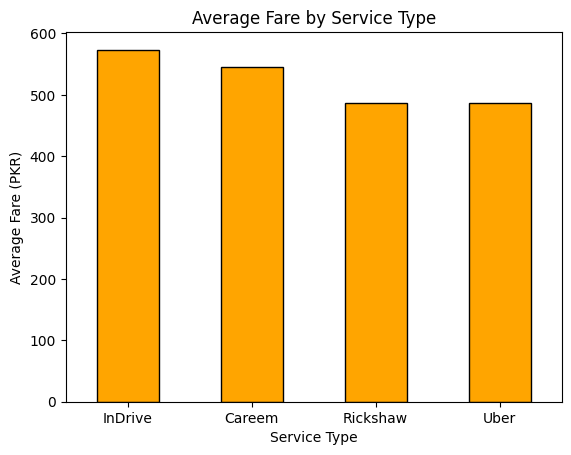

In [8]:
avg_fare.plot(kind="bar", color="orange", edgecolor="black")
plt.title("Average Fare by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Average Fare (PKR)")
plt.xticks(rotation=0)
plt.show()

The chart shows InDrive is the most expensive service on average, while Uber and Rickshaw are the cheapest. Their average fares are almost identical.
